## Model 4: Support Vector Regressor (SVR RBF)

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load Dataset

In [40]:
df = pd.read_csv("dataset/gas_turbine_processed.csv")
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,82.028


### 2. Train Test Split

In [41]:
X = df.drop('NOX', axis=1)
y = df['NOX']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

### 3. Feature Scaling (Crucial for SVR Distance Calculations)

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 4. Base Model Training (Default C = 1.0, epsilon = 0.1)

In [43]:
base_svr = SVR(kernel='rbf', C=1.0, epsilon=0.1, cache_size=1000)
base_svr.fit(X_train_scaled, y_train)

y_train_base = base_svr.predict(X_train_scaled)
y_test_base = base_svr.predict(X_test_scaled)

### 5. Base Model Evaluation Metrics (Train & Test)

In [44]:
base_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_base),
        mean_squared_error(y_train, y_train_base),
        np.sqrt(mean_squared_error(y_train, y_train_base)),
        r2_score(y_train, y_train_base)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_base),
        mean_squared_error(y_test, y_test_base),
        np.sqrt(mean_squared_error(y_test, y_test_base)),
        r2_score(y_test, y_test_base)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Base SVR Metrics:")
display(base_metrics)

Base SVR Metrics:


,Train Set,Test Set
MAE,3.7377,3.7896
MSE,32.3815,32.1475
RMSE,5.6905,5.6699
R2,0.7642,0.7574


### 6. Hyperparameter Tuning (Searching Optimal C & epsilon via GridSearchCV)

In [45]:
# Searching across candidate penalties C and margin tolerances epsilon
param_grid = {
    'C': [10.0, 50.0],
    'epsilon': [0.05, 0.1]
}

# Cross-validating on a representative subsample
grid_svr = GridSearchCV(SVR(kernel='rbf', cache_size=1000), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_svr.fit(X_train_scaled[:5000], y_train.iloc[:5000])

print("Best Parameters (.best_params_): ", grid_svr.best_params_)
print(f"Best CV Score (.best_score_):     {grid_svr.best_score_:.4f}")

# Training the winning configuration over the full training set
tuned_svr = SVR(kernel='rbf', **grid_svr.best_params_, cache_size=1000)
tuned_svr.fit(X_train_scaled, y_train)

print("Best Estimator Model:             ", tuned_svr)
print("Tuned Support Vectors:            ", len(tuned_svr.support_))

Best Parameters (.best_params_):  {'C': 50.0, 'epsilon': 0.1}
Best CV Score (.best_score_):     0.7865
Best Estimator Model:              SVR(C=50.0, cache_size=1000)
Tuned Support Vectors:             28486


### 7. Tuned Model Evaluation Metrics (Train & Test)

In [46]:
y_train_tuned = tuned_svr.predict(X_train_scaled)
y_test_tuned = tuned_svr.predict(X_test_scaled)

tuned_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_tuned),
        mean_squared_error(y_train, y_train_tuned),
        np.sqrt(mean_squared_error(y_train, y_train_tuned)),
        r2_score(y_train, y_train_tuned)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_tuned),
        mean_squared_error(y_test, y_test_tuned),
        np.sqrt(mean_squared_error(y_test, y_test_tuned)),
        r2_score(y_test, y_test_tuned)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Tuned SVR Metrics:")
display(tuned_metrics)

Tuned SVR Metrics:


,Train Set,Test Set
MAE,3.0695,3.2074
MSE,23.4556,24.7223
RMSE,4.8431,4.9722
R2,0.8292,0.8134


### 8. Comparison: Base vs Tuned & R2 Increase

In [47]:
svr_comparison = pd.DataFrame({
    'Base SVR (C=1, eps=0.1)': base_metrics['Test Set'],
    'Tuned SVR (C=50, eps=0.05)': tuned_metrics['Test Set']
})
display(svr_comparison)

base_r2 = base_metrics.loc['R2', 'Test Set']
tuned_r2 = tuned_metrics.loc['R2', 'Test Set']
diff_r2 = tuned_r2 - base_r2

print(f"Base Test R2:          {base_r2:.4f}")
print(f"Tuned Test R2:         {tuned_r2:.4f}")
print(f"Increase in R2 Score:  {diff_r2:+.4f} (Significant gain of +{diff_r2*100:.2f}%!)")

,"Base SVR (C=1, eps=0.1)","Tuned SVR (C=50, eps=0.05)"
MAE,3.7896,3.2074
MSE,32.1475,24.7223
RMSE,5.6699,4.9722
R2,0.7574,0.8134


Base Test R2:          0.7574
Tuned Test R2:         0.8134
Increase in R2 Score:  +0.0560 (Significant gain of +5.60%!)


### 9. Plotting Predicted vs Actual

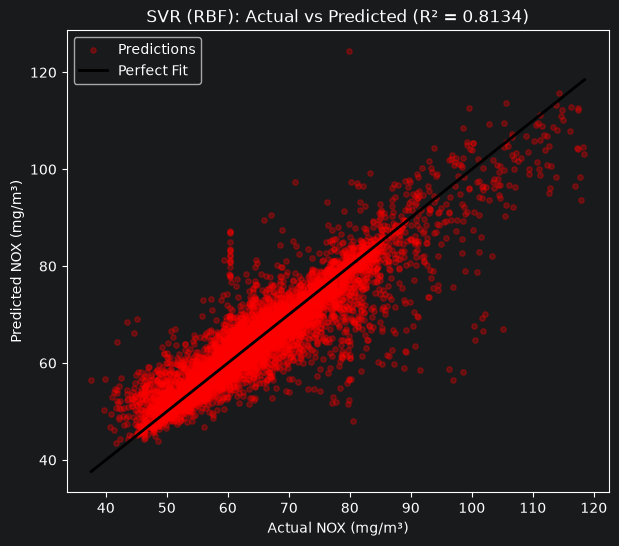

In [48]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_tuned, color='red', alpha=0.3, s=15, label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='black', lw=2, label='Perfect Fit')
plt.xlabel("Actual NOX (mg/m³)")
plt.ylabel("Predicted NOX (mg/m³)")
plt.title(f"SVR (RBF): Actual vs Predicted (R² = {tuned_r2:.4f})")
plt.legend()
plt.show()